# Explore the Federal Reserve US Treasury zero-coupon curve

Federal Reserve (Gurkaynak-Sack-Wright) Treasury zero-coupon curve, percent, continuously compounded, daily (`load_curve("US")`). The 30Y starts 1985-11. The longest history of the three; a candidate for pooled training of the neural SDE.

Same exploration for each of the three datasets (`01_ecb_aaa`, `02_bundesbank_de`, `03_fed_us`).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller, kpss
from scenario_lab.data import load_curve
plt.style.use("default"); plt.rcParams["figure.facecolor"] = "white"  # undo IDE dark-theme recolouring
warnings.filterwarnings("ignore")  # statsmodels API/table-range warnings; KPSS p is clipped to [0.01, 0.1]

d = load_curve("US")
MATS = [1, 2, 5, 10, 20, 30]
print(d.shape, d.index.min().date(), d.index.max().date(), "NaN:", int(d.isna().sum().sum()))
d.describe().round(2)

(10228, 6) 1985-11-25 2026-11-13 NaN: 0


,1Y,2Y,5Y,10Y,20Y,30Y
count,10228.00,10228.00,10228.00,10228.00,10228.00,10228.00
mean,3.48,3.68,4.21,4.81,5.27,5.28
std,2.53,2.51,2.36,2.22,2.11,2.02
min,0.06,0.10,0.22,0.52,0.96,1.25
25%,0.94,1.23,2.06,2.90,3.48,3.57
50%,3.67,3.91,4.07,4.53,5.02,4.95
75%,5.48,5.66,6.03,6.45,6.83,6.88
max,9.80,9.73,9.75,10.18,10.45,10.76


## 1. History of each maturity

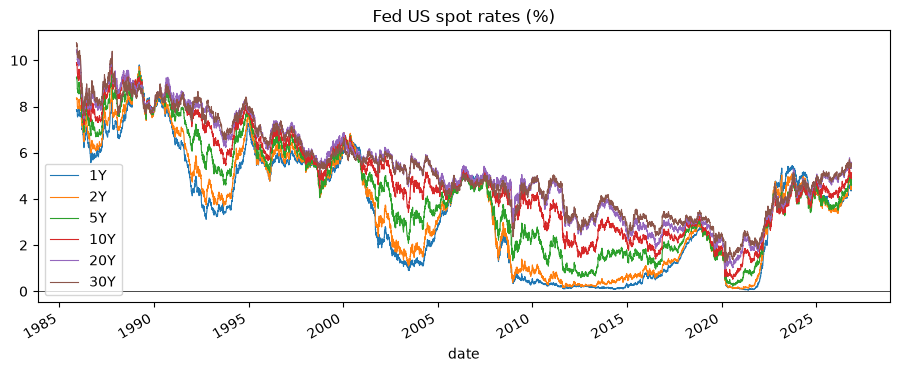

In [2]:
d.plot(figsize=(11, 4), lw=0.8, title="Fed US spot rates (%)"); plt.axhline(0, c="k", lw=0.5); plt.show()

## 2. Curve shapes on selected dates

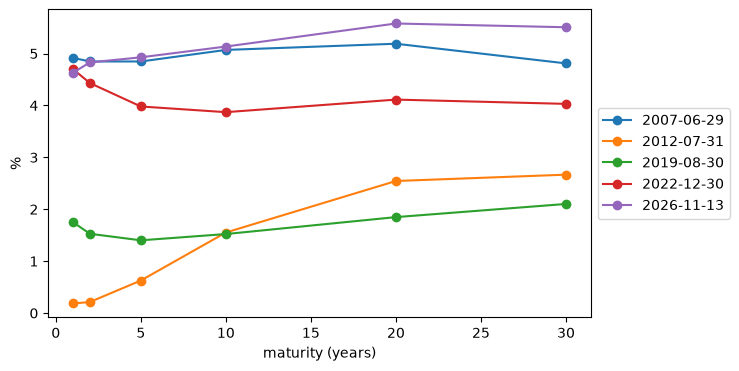

In [3]:
dates = ["2007-06-29", "2012-07-31", "2019-08-30", "2022-12-30", "2100-01-01"]      # last entry = latest available day
fig, ax = plt.subplots(figsize=(7, 4))
for dt in dates:
    r = d.loc[:dt].iloc[-1]
    ax.plot(MATS, r.values, marker="o", label=str(r.name.date()))
ax.set(xlabel="maturity (years)", ylabel="%"); ax.legend(loc="center left", bbox_to_anchor=(1, 0.5)); plt.show()

## 3. Rate changes (weekly, Friday-to-Friday) and cross-maturity correlation

In [4]:
w = d.resample("W-FRI").last()
dw = w.diff().dropna()
print(dw.describe().round(3).loc[["std", "min", "max"]])
print("excess kurtosis:\n", dw.kurt().round(2))
print(dw.corr().round(2))

        1Y     2Y     5Y    10Y    20Y    30Y
std  0.106  0.124  0.134  0.132  0.125  0.130
min -1.242 -1.212 -1.098 -1.079 -1.068 -1.062
max  0.549  0.612  0.630  0.549  0.509  0.631
excess kurtosis:
 1Y     13.14
2Y      6.60
5Y      3.00
10Y     2.95
20Y     3.65
30Y     3.85
dtype: float64
       1Y    2Y    5Y   10Y   20Y   30Y
1Y   1.00  0.95  0.81  0.65  0.53  0.48
2Y   0.95  1.00  0.92  0.77  0.64  0.55
5Y   0.81  0.92  1.00  0.93  0.80  0.70
10Y  0.65  0.77  0.93  1.00  0.94  0.78
20Y  0.53  0.64  0.80  0.94  1.00  0.85
30Y  0.48  0.55  0.70  0.78  0.85  1.00


## 4. Stationarity: levels vs weekly changes

ADF null: unit root. KPSS null: stationary. Read them together; ADF has low power on persistent series.

In [5]:
rows = []
for name, s in [("level", w), ("change", dw)]:
    for c in s.columns:
        rows.append((name, c, adfuller(s[c], autolag="AIC")[1], kpss(s[c], regression="c", nlags="auto")[1]))
res = pd.DataFrame(rows, columns=["series", "mat", "ADF p", "KPSS p"]).round(3)
res.pivot(index="mat", columns="series", values=["ADF p", "KPSS p"]).reindex([f"{m}Y" for m in MATS])

ADF p        KPSS p      
series change  level change level
mat                              
1Y        0.0  0.325    0.1  0.01
2Y        0.0  0.278    0.1  0.01
5Y        0.0  0.274    0.1  0.01
10Y       0.0  0.244    0.1  0.01
20Y       0.0  0.192    0.1  0.01
30Y       0.0  0.116    0.1  0.01

## 5. Volatility clustering: rolling 1-year std of weekly changes

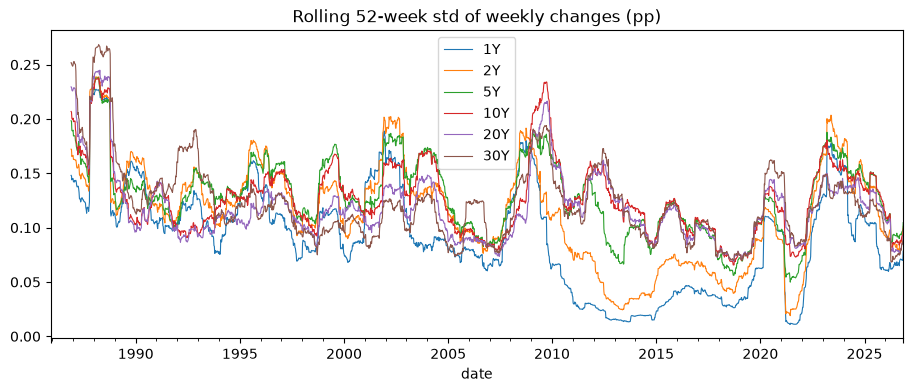

In [6]:
dw.rolling(52).std().plot(figsize=(11, 4), lw=0.8, title="Rolling 52-week std of weekly changes (pp)"); plt.show()

## 6. Relation to ECB AAA

Correlation of 10Y changes over different horizons, and a lead/lag check, on the days both curves are available. The US value is the New York close, later in the day than the ECB value, so daily changes are not synchronous.

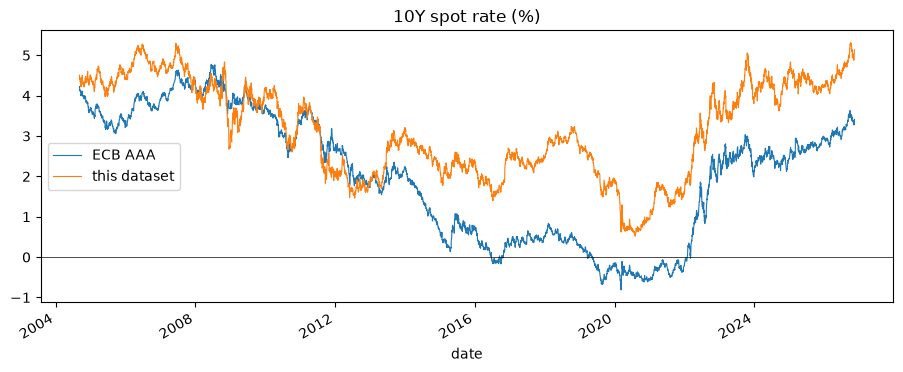

correlation of 10Y changes with ECB AAA, by horizon
1-day     0.50
5-day     0.70
20-day    0.74
60-day    0.78
dtype: float64
mean 10Y level gap (this dataset - AAA, pp): 1.12
corr(ECB AAA change on day t, this dataset change on day t+k)
-2    0.01
-1    0.24
0     0.50
1    -0.01
2     0.01
dtype: float64
lag-1 autocorrelation of daily changes: ECB AAA 0.029 | this dataset -0.01


In [7]:
aaa = load_curve("AAA")
c10 = pd.concat({"ECB AAA": aaa["10Y"], "this dataset": d["10Y"]}, axis=1, sort=True).dropna()
c10.plot(figsize=(11, 4), lw=0.8, title="10Y spot rate (%)"); plt.axhline(0, c="k", lw=0.5); plt.show()
print("correlation of 10Y changes with ECB AAA, by horizon")
print(pd.Series({f"{h}-day": c10.diff(h).dropna().corr().iloc[0, 1] for h in (1, 5, 20, 60)}).round(2))
print("mean 10Y level gap (this dataset - AAA, pp):", round((c10["this dataset"] - c10["ECB AAA"]).mean(), 2))
d1 = c10.diff().dropna()
a, b = d1["ECB AAA"], d1["this dataset"]
print("corr(ECB AAA change on day t, this dataset change on day t+k)")
print(pd.Series({k: a.corr(b.shift(-k)) for k in (-2, -1, 0, 1, 2)}).round(2))
print("lag-1 autocorrelation of daily changes: ECB AAA", round(a.autocorr(1), 3), "| this dataset", round(b.autocorr(1), 3))

## Observations

- **Sample:** 10,228 days from 1985-11 to 2026-11 (41.0 years), rates from 0.06% to 10.8%. The high-rate 1980s-90s regime has no counterpart in the euro samples, and there are no negative rates.
- **Weekly changes:** std 0.11 pp (1Y) to 0.13 pp (30Y), 1.2 to 1.5 times the ECB series. Excess kurtosis 13 at 1Y, 3-4 at the other maturities (more fat-tailed at the long end than the euro series).
- **Stationarity:** unit root not rejected in the levels (p 0.12-0.33), rejected for changes; KPSS rejects stationary levels and does not reject for the changes.
- **Relation to ECB AAA:** 10Y changes correlate 0.50 daily, 0.70 over 5 days and 0.78 over 60 days (different markets and closing times); the ECB change on day t correlates 0.50 with the US change on day t and 0.24 with the US change on day t-1. The 10Y level is on average 1.1 pp above AAA.